In [2]:
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

# 1. Selección del dispositivo de cómputo (CPU Intel i5)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SETUP] Dispositivo en uso: {device}")

# 2. Fijación de semilla global para reproducibilidad científica
SEED = 42

def set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)

set_seed(SEED)
print(f"[SETUP] Semilla global fijada en: {SEED}")

[SETUP] Dispositivo en uso: cpu
[SETUP] Semilla global fijada en: 42


In [3]:
# Ruta de la carpeta raíz que contiene 'train' y 'test'
DATASET_PATH = "./fase_2/secondo_archiviio/sample_10k/" 
print(os.path.join(DATASET_PATH, "train"))
# Pipeline de transformación:
# Se fuerza Resize(128, 128) por seguridad para garantizar dimensiones uniformes
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# Carga de los conjuntos desde el sistema de archivos
train_dataset = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "train"), transform=transform)
test_dataset  = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "test"),  transform=transform)

print(f"[DATOS] Mapeo de clases: {train_dataset.class_to_idx}")
print(f"[DATOS] Muestras Train: {len(train_dataset)} | Muestras Test: {len(test_dataset)}")

# Batch size reducido a 32 para optimizar la caché de la CPU Intel i5 con imágenes 128x128
# num_workers=0 evita cuellos de botella de multiprocesamiento en Windows
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

./fase_2/secondo_archiviio/sample_10k/train
[DATOS] Mapeo de clases: {'fake': 0, 'real': 1}
[DATOS] Muestras Train: 16022 | Muestras Test: 4005


In [4]:
class BaselineMLP128(nn.Module):
    def __init__(self):
        super(BaselineMLP128, self).__init__()
        # Aplanamiento: 128 * 128 * 3 canales = 49,152 características de entrada
        self.flatten = nn.Flatten()
        
        # Arquitectura optimizada para CPU: reducción progresiva para controlar el número de parámetros
        self.classifier = nn.Sequential(
            nn.Linear(128 * 128 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),  # Dropout aumentado para mitigar overfitting en vectores grandes
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)  # Salida binaria (fake / real)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.classifier(x)

model = BaselineMLP128().to(device)

# Conteo de parámetros entrenables para verificar carga computacional
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n[ARQUITECTURA] Total de parámetros entrenables: {total_params:,}")

BaselineMLP128(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=49152, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)

[ARQUITECTURA] Total de parámetros entrenables: 6,299,970


In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 8 épocas compensan el menor volumen de imágenes (16k frente a 100k)
EPOCHS = 8
start_total_time = time.time()

print(f"[ENTRENAMIENTO] Iniciando sesión en {device.type.upper()}...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    epoch_start = time.time()
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        # 1. Reiniciar gradientes acumulados
        optimizer.zero_grad()
        # 2. Propagación hacia adelante (Forward pass)
        outputs = model(images)
        # 3. Cálculo del error
        loss = criterion(outputs, labels)
        # 4. Retropropagación y actualización de pesos
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_duration = time.time() - epoch_start
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    
    print(f"Época {epoch+1:02d}/{EPOCHS:02d} | Tiempo: {epoch_duration:.1f}s | "
          f"Pérdida: {epoch_loss:.4f} | Precisión Train: {epoch_acc:.2f}%")

total_training_time = time.time() - start_total_time
print(f"\n[ENTRENAMIENTO] Finalizado en {total_training_time:.2f} segundos.")

[ENTRENAMIENTO] Iniciando sesión en CPU...
Época 01/08 | Tiempo: 83.6s | Pérdida: 0.7478 | Precisión Train: 60.29%
Época 02/08 | Tiempo: 59.5s | Pérdida: 0.6170 | Precisión Train: 66.28%
Época 03/08 | Tiempo: 63.3s | Pérdida: 0.5751 | Precisión Train: 69.99%
Época 04/08 | Tiempo: 51.4s | Pérdida: 0.5458 | Precisión Train: 71.92%
Época 05/08 | Tiempo: 50.2s | Pérdida: 0.5243 | Precisión Train: 73.72%
Época 06/08 | Tiempo: 50.8s | Pérdida: 0.5043 | Precisión Train: 75.08%
Época 07/08 | Tiempo: 54.2s | Pérdida: 0.4905 | Precisión Train: 76.20%
Época 08/08 | Tiempo: 52.3s | Pérdida: 0.4649 | Precisión Train: 77.44%

[ENTRENAMIENTO] Finalizado en 465.40 segundos.


[TEST] Evaluando rendimiento en 4005 imágenes de prueba...

[EFICIENCIA] Latencia media de inferencia: 0.2113 ms/imagen

[MÉTRICAS] Informe de Clasificación:
              precision    recall  f1-score   support

        fake     0.7642    0.7650    0.7646      2000
        real     0.7654    0.7646    0.7650      2005

    accuracy                         0.7648      4005
   macro avg     0.7648    0.7648    0.7648      4005
weighted avg     0.7648    0.7648    0.7648      4005



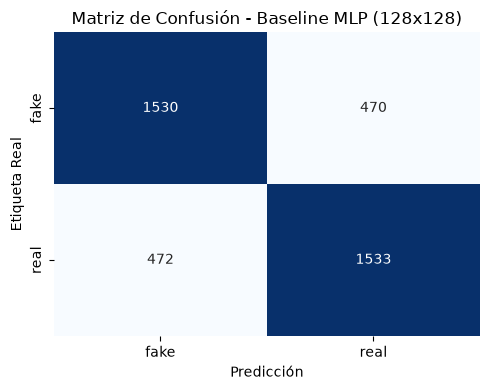


[EXPORTACIÓN] Pesos guardados exitosamente en 'baseline_mlp_128.pth'


In [5]:
model.eval()
all_preds = []
all_labels = []
inference_times = []

print(f"[TEST] Evaluando rendimiento en {len(test_dataset)} imágenes de prueba...")

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        # Medición precisa de latencia de inferencia por imagen
        t0 = time.perf_counter()
        outputs = model(images)
        t1 = time.perf_counter()
        
        batch_size_curr = images.size(0)
        inference_times.append((t1 - t0) / batch_size_curr)
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 1. Latencia media de inferencia
avg_latency_ms = np.mean(inference_times) * 1000
print(f"\n[EFICIENCIA] Latencia media de inferencia: {avg_latency_ms:.4f} ms/imagen")

# 2. Informe formal de métricas
class_names = list(train_dataset.class_to_idx.keys())
print("\n[MÉTRICAS] Informe de Clasificación:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 3. Visualización de la Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta Real")
plt.title("Matriz de Confusión - Baseline MLP (128x128)")
plt.tight_layout()
plt.show()

# 4. Guardado del modelo entrenado en disco
SAVE_PATH = "baseline_mlp_128.pth"
torch.save(model.state_dict(), SAVE_PATH)
print(f"\n[EXPORTACIÓN] Pesos guardados exitosamente en '{SAVE_PATH}'")

[AVISO] No se encontró el archivo: '.\imagen_cara_gemini_1.jpg'


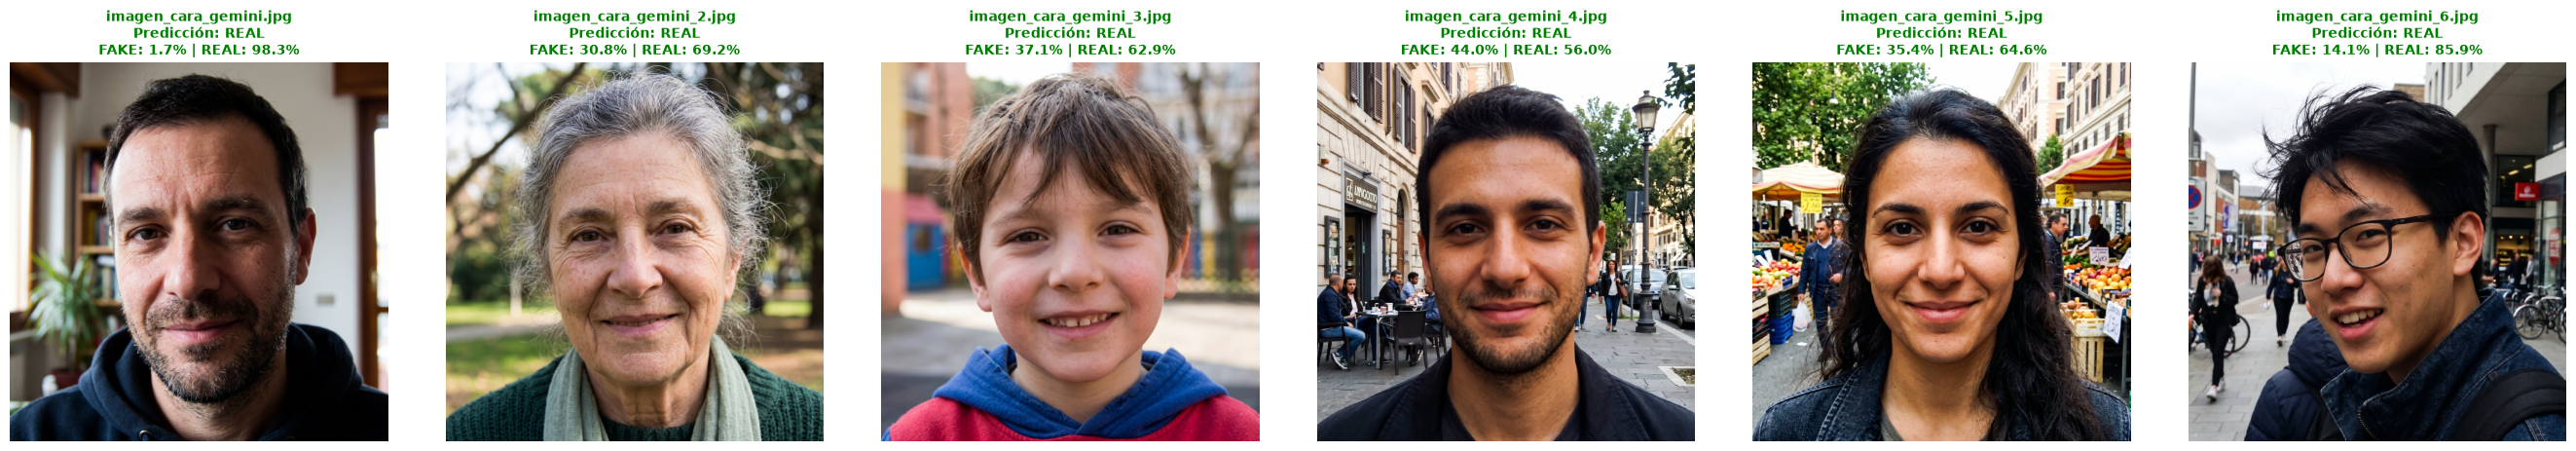

In [18]:
import os
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# --- CONFIGURACIÓN DE LA PRUEBA MANUAL (128x128) ---
# Carpeta donde se encuentran las imágenes (ej. "." para la carpeta actual del notebook, o "test/fake")
CARPETA_IMAGENES = "."
# LISTA_IMAGENES = [
#     "foto_fake_1.jpg",
#     "foto_fake_2.jpg",
#     "foto_fake_3.jpg",
#     "foto_fake_4.jpg",
#     "foto_fake_5.jpg",
#     "foto_fake_del_dataset_1.jpg",
#     "foto_fake_del_dataset_2.jpg",
#     "foto_fake_del_dataset_3.jpg",
#     "foto_fake_del_dataset_4.jpg"
# ]
LISTA_IMAGENES = [
    "imagen_cara_gemini.jpg",
    "imagen_cara_gemini_1.jpg",
    "imagen_cara_gemini_2.jpg",
    "imagen_cara_gemini_3.jpg",
    "imagen_cara_gemini_4.jpg",
    "imagen_cara_gemini_5.jpg",
    "imagen_cara_gemini_6.jpg"
]

WEIGHTS_FILE = "baseline_mlp_128.pth"

# 1. Cargar el modelo 128x128 desde disco
test_model = BaselineMLP128().to(device)
test_model.load_state_dict(torch.load(WEIGHTS_FILE, map_location=device))
test_model.eval()

# 2. Preprocesamiento fijo a 128x128 idéntico al entrenamiento
infer_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# 3. Filtrar las imágenes válidas que existen en la carpeta
imagenes_validas = []
for nombre in LISTA_IMAGENES:
    ruta_completa = os.path.join(CARPETA_IMAGENES, nombre)
    if os.path.exists(ruta_completa):
        imagenes_validas.append((nombre, ruta_completa))
    else:
        print(f"[AVISO] No se encontró el archivo: '{ruta_completa}'")

# 4. Predicción y visualización en fila (una al lado de la otra)
num_imgs = len(imagenes_validas)

if num_imgs > 0:
    fig, axes = plt.subplots(1, num_imgs, figsize=(4.5 * num_imgs, 4.5))
    
    # Si solo hay 1 imagen válida, convertir 'axes' en lista para mantener compatibilidad
    if num_imgs == 1:
        axes = [axes]
        
    for ax, (nombre, ruta) in zip(axes, imagenes_validas):
        raw_img = Image.open(ruta).convert("RGB")
        input_tensor = infer_transform(raw_img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            logits = test_model(input_tensor)
            probs = F.softmax(logits, dim=1)[0]
            
        prob_fake = probs[0].item() * 100
        prob_real = probs[1].item() * 100
        
        pred_idx = torch.argmax(probs).item()
        veredicto = "FAKE (IA)" if pred_idx == 0 else "REAL"
        color_titulo = "red" if pred_idx == 0 else "green"
        
        ax.imshow(raw_img)
        ax.set_title(
            f"{nombre}\nPredicción: {veredicto}\nFAKE: {prob_fake:.1f}% | REAL: {prob_real:.1f}%",
            color=color_titulo,
            fontsize=10,
            fontweight="bold"
        )
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()
else:
    print("[ERROR] Ninguna de las imágenes de la lista fue encontrada.")